In [9]:
import pandas as pd
from pathlib import Path

RAW_DATA_PATH = Path("../Data/Raw/PhiUSIIL_Phishing_URL_Dataset.csv")

df = pd.read_csv(RAW_DATA_PATH, usecols=['URL', 'label']).rename(columns={'URL': 'url'})
print("Số lượng url PhiUSIIL ban đầu: ", len(df))
df.head()

Số lượng url PhiUSIIL ban đầu:  235795


,url,label
0,https://www.southbankmosaics.com,0
1,https://www.uni-mainz.de,0
2,https://www.voicefmradio.co.uk,0
3,https://www.sfnmjournal.com,0
4,https://www.rewildingargentina.org,0


In [10]:
print("Số giá trị rỗng: ")
print(df.isnull().sum())
# Xóa bỏ các ô rỗng
df = df.dropna()

Số giá trị rỗng: 
url      0
label    0
dtype: int64


In [11]:
# Kiểm tra giá trị trùng lặp
print("Số URL bị trùng lặp: ", df.duplicated(subset=['url']).sum())
# Xóa các url trùng lặp
df = df.drop_duplicates(subset=['url'])

print("Số lượng url PhiUSIIL sau khi làm sạch: ", len(df))

Số URL bị trùng lặp:  425
Số lượng url PhiUSIIL sau khi làm sạch:  235370


In [12]:
EXTRA_BENIGN_PATH = Path("../Data/Raw/benign_urls_with_path.csv")

df_extra = pd.read_csv(EXTRA_BENIGN_PATH, usecols=['url', 'label'])
print("Số lượng URL lành tính bổ sung: ", len(df_extra))


n_phish = (df['label'] == 1).sum()
n_phi_benign = n_phish - len(df_extra)

df_benign = pd.concat([
    df[df['label'] == 0].sample(n=n_phi_benign, random_state=42),
    df_extra
])
df = pd.concat([df_benign, df[df['label'] == 1]], ignore_index=True)

print("Số lượng url sau khi cân bằng: ", len(df))
df.tail()

Số lượng URL lành tính bổ sung: 

 15000
Số lượng url sau khi cân bằng:  201040


,url,label
201035,https://ww.prestamo.enlinea.pe.vpphoangha.vn/,1
201036,http://goldenrod-motley-texture.glitch.me/hvwa...,1
201037,https://bancolombia.com1home0892.repl.co/?2,1
201038,https://aol-108318.weeblysite.com/,1
201039,https://patient-cell-40f5.updatedlogmylogin.wo...,1


In [13]:
# Đếm tỷ lệ nhãn
df['label'].value_counts()

label
0    100520
1    100520
Name: count, dtype: int64

[Text(0, 3, '100,520'), Text(0, 3, '100,520')]

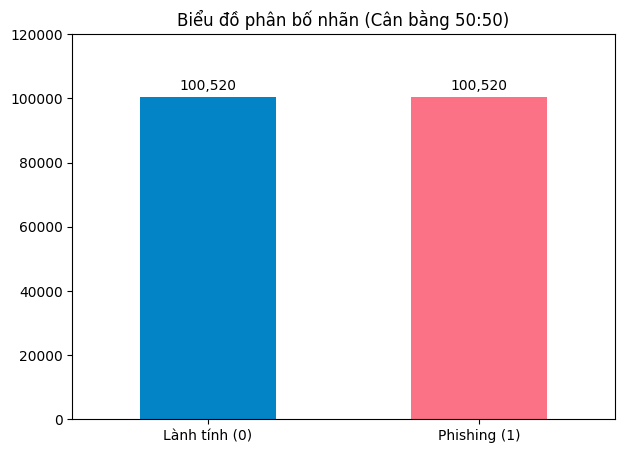

In [14]:
# Vẽ biểu đồ phân bố nhãn
counts = df['label'].value_counts().sort_index()
counts.index = ['Lành tính (0)', 'Phishing (1)']

ax = counts.plot(
    kind='bar',
    color=['#0284c7', '#fb7185'],
    rot=0,
    title='Biểu đồ phân bố nhãn (Cân bằng 50:50)',
    figsize=(7, 5),
)
ax.set_ylim(0, 120000)
ax.bar_label(ax.containers[0], fmt=lambda x: f'{int(x):,}', padding=3)


In [15]:
OUTPUT_PATH = Path("../Data/Interim/urls_cleaned.csv")

df.to_csv(OUTPUT_PATH, index=False)
